# Bayesian Inference with Spectral Constraints: CTCV J2056-3014

This notebook extends the analysis from `07_bayesian_inference.ipynb` by incorporating X-ray spectral constraints ($L_X$ and $kT_{\text{max}}$) directly into the likelihood. This addresses the M–$\dot{M}$ prior correlation from spectral fitting (Salcedo+2024) by replacing informative spectral mass priors with broad population priors, and letting the spectral observables constrain the parameters through the physics.

**Data sources:**
- $\dot{P}_{\rm obs} = 0.0 \pm 1.7 \times 10^{-15}$ s/s (Salcedo+2024, Section 3.3)
- $L_X = 1.8 \times 10^{31}$ erg/s (0.3–12 keV, low state; Salcedo+2024)
- $kT_{\rm max} = 16.3^{+1.9}_{-1.8}$ keV (MKCFLOW; Salcedo+2024, Table 6)

In [17]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.stats import norm
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import corner
import dynesty
from dynesty import utils as dyfunc
from dynesty import plotting as dyplot

plt.rcParams.update({
    'font.size': 17,
    'axes.labelsize': 17,
    'xtick.labelsize': 17,
    'ytick.labelsize': 17,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'figure.constrained_layout.use': True,
})

savedir = '../paper_figures' 

## Constants, Data, and WD Mass-Radius-Inertia Relation

In [18]:
# --- Physical constants (CGS) ---
G = 6.674e-8       # cm^3 g^-1 s^-2
Msun = 1.989e33    # g
Rsun = 6.957e10    # cm
m_H = 1.6726e-24   # proton mass [g]
keV_to_erg = 1.602e-9  # keV -> erg

# --- Measured timing data (1-sigma) ---
P = 29.609685843       # spin period [s]
Pdot_obs = 0.0         # observed Pdot [s/s]
sigma_Pdot = 1.7e-15   # 1-sigma uncertainty on Pdot [s/s]

# --- Spectral observables (Salcedo+2024) ---
# X-ray luminosity: F_X(unabs, 0.3-12 keV) = 2.2e-12 erg/s/cm^2, d = 261.6 +/- 7.4 pc
d_pc = 261.6                           # distance [pc]
sigma_d_pc = 7.4                       # 1-sigma distance error [pc]
d_cm = d_pc * 3.086e18                 # distance [cm]
F_X = 2.2e-12                          # unabsorbed flux [erg/s/cm^2]
sigma_FX_frac = 0.05                   # ~5% flux uncertainty (spectral fit)
sigma_FX_frac = 0.2
L_X_obs = 4 * np.pi * d_cm**2 * F_X   # X-ray luminosity [erg/s], 0.3-12 keV band
# Propagate distance + flux uncertainties
sigma_LX = L_X_obs * np.sqrt((2 * sigma_d_pc / d_pc)**2 + sigma_FX_frac**2)

# X-ray band for the bolometric -> band-limited correction applied to L_X_pred
LX_BAND_LO = 0.3   # keV
LX_BAND_HI = 12.0  # keV

# kT_max from MKCFLOW (Salcedo+2024, Table 6)
# 90% CI: 16.3 +1.9/-1.8 keV -> 1-sigma ~ 1.9/1.645 ~ 1.15 keV
kT_obs = 16.3        # keV
sigma_kT = 1.15       # 1-sigma [keV]
sigma_kT = 3

# Mean molecular weight for fully ionized solar-composition plasma
mu_mol = 0.617

# --- Load WD mass-radius-inertia table ---
mr_data = np.loadtxt('../wd_mass_radius/mass_radius.txt', delimiter=',', skiprows=1)
M_table = mr_data[:, 0]   # M_sun
R_table = mr_data[:, 1]   # R_sun
I_table = mr_data[:, 2]   # g cm^2

# Interpolators: input in solar masses, output in CGS
get_R = interp1d(M_table, R_table * Rsun, kind='cubic')   # returns cm
get_I = interp1d(M_table, I_table, kind='cubic')           # returns g cm^2

M_min_table = M_table.min()
M_max_table = M_table.max()

# --- Magnetosphere geometry ---
# xi: magnetospheric-radius prefactor, r_m = xi * r_Alfven (Ghosh & Lamb 1979).
#     Conventional disk-accretion value is ~0.5, literature range ~0.3-1.
#     Since r_m ~ B^(4/7), the inferred B scales as xi^(-7/4); a factor-2
#     uncertainty in xi maps to ~3.4x on B. We marginalise over xi as a
#     sampled nuisance parameter so the B posterior reflects this systematic.

print(f"Table range: {M_min_table:.3f} - {M_max_table:.3f} Msun")
print(f"L_X_obs = {L_X_obs:.2e} erg/s  (sigma = {sigma_LX:.2e})")
print(f"kT_obs  = {kT_obs:.1f} +/- {sigma_kT:.2f} keV (1-sigma)")


Table range: 0.010 - 1.406 Msun
L_X_obs = 1.80e+31 erg/s  (sigma = 3.74e+30)
kT_obs  = 16.3 +/- 3.00 keV (1-sigma)


## Forward Models

We model CJ2056 as an **accreting intermediate polar**. The observed hard thermal X-ray emission ($kT \approx 16$ keV, $L_X \approx 10^{31}$ erg/s) is an accretion-shock signature, so we restrict the IP model to $r_m \in [R_{\rm WD}, r_{\rm co}]$ (no propeller regime) throughout.

**Pdot** follows Bhattacharyya & Chakrabarty (2017, Eq. 9) in the accretion regime.

**Spectral forward models:**
- $kT_{\text{pred}} = \frac{3}{16} \mu_{\text{mol}} m_H \cdot 2GM\left(\frac{1}{R} - \frac{1}{r_m}\right)$ (Rankine-Hugoniot strong shock, $\gamma = 5/3$)
- $L_{X,\text{pred}} = f_{\rm band}(kT_{\rm pred}) \cdot GM\dot{M}\left(\frac{1}{R} - \frac{1}{r_m}\right)$

Samples with $r_m \le R_{\rm WD}$ or $r_m > r_{\rm co}$ are rejected by the likelihood (forward models return NaN).

**Band correction.** Theoretical accretion luminosities are bolometric, whereas $L_{X,\rm obs}$ is the unabsorbed flux in 0.3-12 keV. For single-temperature thermal bremsstrahlung with Gaunt factor $g_{\rm ff} \approx 1$,
$$f_{\rm band}(kT) = \exp(-E_{\rm lo}/kT) - \exp(-E_{\rm hi}/kT),$$
evaluated at the predicted $kT$. At $kT \sim 16$ keV this gives $f_{\rm band} \approx 0.5$.


In [19]:
# =====================================================
# Pdot forward model (Bhattacharyya & Chakrabarty 2017)
# =====================================================

def _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Return (M, Mdot, mu, R, r_m, r_co) in CGS for an accreting IP."""
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    R = get_R(M_wd_solar)
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)
    return M, Mdot, mu, R, r_m, r_co


def pdot_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted Pdot for an accreting IP (r_m in [R_WD, r_co]).

    Bhattacharyya & Chakrabarty (2017, Eq. 9). Returns NaN outside the accretion
    range (r_m <= R_WD or r_m > r_co).
    """
    M, Mdot, mu, R, r_m, r_co = _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi)
    I = get_I(M_wd_solar)
    if r_m <= R or r_m > r_co:
        return np.nan

    x = r_m / r_co
    tau_acc = Mdot * np.sqrt(G * M * r_m)
    tau_mag = mu**2 / (9 * r_m**3) * (2 * x**3 - 6 * x**1.5 + 3)
    return -P**2 * (tau_acc + tau_mag) / (2 * np.pi * I)


# =====================================================
# Band-correction factor for the bolometric -> 0.3-12 keV conversion
# =====================================================

def f_band(kT_keV):
    """Fraction of bolometric thermal-bremsstrahlung luminosity in LX_BAND_LO..LX_BAND_HI.

    Single-temperature bremsstrahlung with Gaunt factor ~1:
        dL/dE ~ exp(-E/kT)  ->  L(E1,E2)/L_bol = exp(-E1/kT) - exp(-E2/kT).
    """
    return np.exp(-LX_BAND_LO / kT_keV) - np.exp(-LX_BAND_HI / kT_keV)


# =====================================================
# Spectral forward models (IP)
# =====================================================

def kT_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted shock temperature for an accreting IP [keV].

    Returns NaN outside the accretion range (r_m <= R_WD or r_m > r_co).
    """
    M, Mdot, mu, R, r_m, r_co = _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi)
    if r_m <= R or r_m > r_co:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT_erg = (3.0 / 16.0) * mu_mol * m_H * vff2
    return kT_erg / keV_to_erg


def LX_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted 0.3-12 keV X-ray luminosity for an accreting IP [erg/s]."""
    M, Mdot, mu, R, r_m, r_co = _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi)
    if r_m <= R or r_m > r_co:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT = (3.0 / 16.0) * mu_mol * m_H * vff2 / keV_to_erg
    L_bol = G * M * Mdot * (1.0 / R - 1.0 / r_m)
    return f_band(kT) * L_bol


# --- Sanity checks ---
print("=== Pdot check ===")
print(f"IP(0.815, 15, 30.3, xi=0.5): Pdot = {pdot_ip(0.815, 15, 30.3, 0.5):.3e}")

print("\n=== f_band checks ===")
print(f"f_band(16.3 keV): {f_band(16.3):.3f}   (0.3-12 keV fraction at kT_obs)")
print(f"f_band(10 keV):   {f_band(10.0):.3f}")
print(f"f_band(30 keV):   {f_band(30.0):.3f}")

print("\n=== kT / L_X checks ===")
print(f"IP kT (0.8, 14.5, 30.0, 0.5): {kT_ip(0.8, 14.5, 30.0, 0.5):.1f} keV")
print(f"IP L_X(0.8, 14.5, 30.0, 0.5): {LX_ip(0.8, 14.5, 30.0, 0.5):.2e} erg/s")


=== Pdot check ===
IP(0.815, 15, 30.3, xi=0.5): Pdot = -3.262e-16

=== f_band checks ===
f_band(16.3 keV): 0.503   (0.3-12 keV fraction at kT_obs)
f_band(10 keV):   0.669
f_band(30 keV):   0.320

=== kT / L_X checks ===
IP kT (0.8, 14.5, 30.0, 0.5): 8.9 keV
IP L_X(0.8, 14.5, 30.0, 0.5): 8.26e+30 erg/s


## Priors and Likelihood

**Priors (IP, 4D):**
- $M_{\rm WD}$: $\mathcal{N}(0.83, 0.20)$ (Pala+2022, volume-limited CV sample), clipped to WD table range
- $\log_{10}\dot{M}$: $\mathcal{U}(13, 17)$ (flat in log-space)
- $\log_{10}\mu$: $\mathcal{U}(29, 35)$ (magnetic dipole moment, G$\,$cm$^3$)
- $\xi$: log-uniform on $[0.3, 1.0]$ (magnetospheric-radius prefactor; Ghosh & Lamb 1979 range)

Sampling $\xi$ marginalises the factor-$\xi^{-7/4}$ systematic in $B$ into the posterior rather than fixing it at a conventional value.

**Likelihood.** All three observables ($\dot P$, $kT$, $L_X$) enter as independent Gaussians:
$$\ln\mathcal{L} = -\tfrac12\!\left[\left(\tfrac{\dot P_{\rm obs} - \dot P_{\rm pred}}{\sigma_{\dot P}}\right)^2 + \left(\tfrac{kT_{\rm obs} - kT_{\rm pred}}{\sigma_{kT}}\right)^2 + \left(\tfrac{L_{X,\rm obs} - L_{X,\rm pred}}{\sigma_{L_X}}\right)^2\right].$$

The IP forward models return NaN outside the accretion range ($r_m \in [R_{\rm WD}, r_{\rm co}]$); those samples are rejected ($\ln\mathcal{L} = -10^{100}$).


In [20]:
# =====================================================
# Population mass prior (Pala+2022) and log10(Mdot) flat prior
# =====================================================

POP_M_MU, POP_M_SIG = 0.81, 0.20
LOGMDOT_LO, LOGMDOT_HI = 13.0, 18.0


# =====================================================
# IP model: 4 parameters [M_wd, log10_Mdot, log10_mu, xi]  (accreting only)
# =====================================================

LOGMU_LO, LOGMU_HI = 29.0, 35.0
XI_LO, XI_HI = 0.3, 1.0  # log-uniform prior range (Ghosh & Lamb 1979)

def prior_transform_ip(u):
    """Map unit cube [0,1]^4 -> IP parameter space."""
    theta = np.empty(4)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    theta[2] = LOGMU_LO + u[2] * (LOGMU_HI - LOGMU_LO)
    theta[3] = 10**(np.log10(XI_LO) + u[3] * (np.log10(XI_HI) - np.log10(XI_LO)))
    return theta


def log_likelihood_ip(theta, sigma_Pdot_use=sigma_Pdot, include_Pdot=True):
    """Accreting-IP log-likelihood with kT + L_X (+ optional Pdot). Samples
    with r_m outside [R_WD, r_co] yield NaN from the forward models and are
    rejected."""
    M_wd, log_Mdot, log_mu, xi_s = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100

    kT_pred = kT_ip(M_wd, log_Mdot, log_mu, xi_s)
    LX_pred = LX_ip(M_wd, log_Mdot, log_mu, xi_s)
    if (np.isnan(kT_pred) or np.isnan(LX_pred)
            or kT_pred <= 0 or LX_pred <= 0):
        return -1e100

    chi2  = ((kT_obs  - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    if include_Pdot:
        Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu, xi_s)
        chi2 += ((Pdot_obs - Pdot_pred) / sigma_Pdot_use)**2
    return -0.5 * chi2


# --- Quick check ---
print(f"log L(IP, accretion):  {log_likelihood_ip([0.8, 14.5, 30.0, 0.5]):.3e}")
print(f"log L(IP, propeller rejected): {log_likelihood_ip([0.8, 14.0, 33.0, 0.5]):.3e}")


log L(IP, accretion):  -6.396e+00
log L(IP, propeller rejected): -1.000e+100


## Nested Sampling

In [21]:
print("Running IP nested sampling (4 params: M_WD, log Mdot, log mu, xi)...")
sampler_ip = dynesty.DynamicNestedSampler(
    log_likelihood_ip, prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(42))
)
sampler_ip.run_nested(print_progress=True)
results_ip = sampler_ip.results
print(f"IP done: logZ = {results_ip['logz'][-1]:.2f} +/- {results_ip['logzerr'][-1]:.2f}")


Running IP nested sampling (4 params: M_WD, log Mdot, log mu, xi)...


27200it [01:14, 366.92it/s, batch: 1 | bound: 3 | nc: 1 | ncall: 557849 | eff(%):  4.504 | loglstar: -1.967 < -0.001 < -0.538 | logz: -7.093 +/-  0.057 | stop:  0.720]                       


IP done: logZ = -7.09 +/- 0.05


## Results

In [22]:
# --- Extract equal-weight posterior samples ---

weights_ip = np.exp(results_ip['logwt'] - results_ip['logz'][-1])
weights_ip /= weights_ip.sum()
samples_ip_eq = dyfunc.resample_equal(results_ip['samples'], weights_ip)

# Derived: B = mu / R^3 (R depends on sampled M_WD)
R_samples_ip = get_R(samples_ip_eq[:, 0])
mu_samples_ip = 10**samples_ip_eq[:, 2]
B_samples_ip = mu_samples_ip / R_samples_ip**3
log10_B_samples_ip = np.log10(B_samples_ip)


# --- Summary statistics ---
def summarize(samples, labels):
    for i, label in enumerate(labels):
        med = np.median(samples[:, i])
        lo, hi = np.percentile(samples[:, i], [16, 84])
        print(f'  {label}: {med:.4f}  (+{hi-med:.4f} / -{med-lo:.4f})')


def fmt(samples, idx):
    """One-line median (+hi / -lo) string for samples[:, idx]."""
    med = np.median(samples[:, idx])
    lo, hi = np.percentile(samples[:, idx], [16, 84])
    return f"{med:.3f} (+{hi-med:.3f}/-{med-lo:.3f})"


print('=== IP posteriors ===')
summarize(samples_ip_eq,
          ['M_WD [Msun]', 'log10(Mdot) [g/s]', 'log10(mu) [G cm^3]', 'xi'])
med_B = np.median(log10_B_samples_ip)
lo_B, hi_B = np.percentile(log10_B_samples_ip, [16, 84])
print(f'  log10(B) [G]: {med_B:.2f}  (+{hi_B-med_B:.2f} / -{med_B-lo_B:.2f})')
print(f'  B [MG]: {10**med_B/1e6:.4f}')
print(f'  B [kG]: {10**med_B/1e3:.2f}')


=== IP posteriors ===
  M_WD [Msun]: 0.8624  (+0.1215 / -0.0836)
  log10(Mdot) [g/s]: 14.7090  (+0.0952 / -0.1114)
  log10(mu) [G cm^3]: 30.0796  (+0.3595 / -0.3313)
  xi: 0.5622  (+0.2696 / -0.1891)
  log10(B) [G]: 3.74  (+0.31 / -0.30)
  B [MG]: 0.0054
  B [kG]: 5.43


### Corner Plots

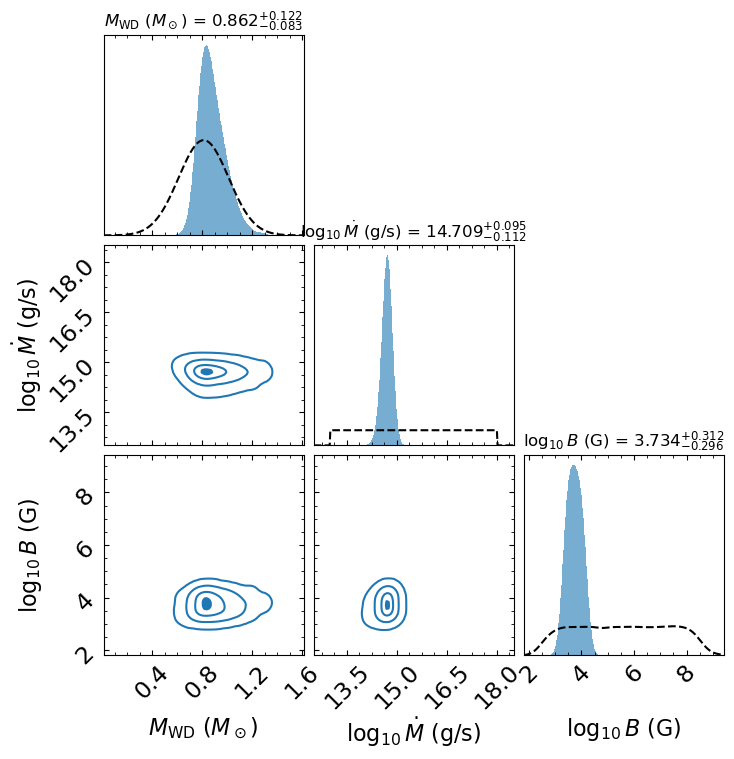

In [23]:
# --- IP corner plot (M_WD, log Mdot, log B) with prior overlays ---
# Modify column 2 in place (logmu -> logB) and use dims=[0, 1, 2] to drop xi
# from the display; xi is marginalised simply by not being plotted.
import copy
from scipy.stats import gaussian_kde


def _results_for_display(results):
    """Deepcopy a dynesty Results object and replace column 2 (log mu) with
    log10 B = log10 mu - 3 log10 R, in place."""
    rcp = copy.deepcopy(results)
    samp = rcp['samples']
    R_arr = get_R(samp[:, 0])
    samp[:, 2] = samp[:, 2] - 3 * np.log10(R_arr)
    return rcp


def overlay_prior(ax, grid, pdf, **kwargs):
    """Scale prior PDF to match histogram area (reads ax.patches from dyplot bars)."""
    hist_area = sum(p.get_width() * p.get_height()
                    for p in ax.patches if p.get_height() > 0)
    if hist_area <= 0:
        return
    prior_area = np.trapezoid(pdf, grid)
    if prior_area <= 0:
        return
    pdf_scaled = pdf * (hist_area / prior_area)
    ax.plot(grid, pdf_scaled, **kwargs)
    ymax = max(ax.get_ylim()[1], pdf_scaled.max() * 1.05)
    ax.set_ylim([0, ymax])


results_ip_B = _results_for_display(results_ip)

# Compute B prior samples for overlay (log-uniform mu marginalised over N(M))
np.random.seed(42)
N_prior = 50000
M_prior = np.random.normal(POP_M_MU, POP_M_SIG, N_prior)
M_prior = np.clip(M_prior, M_min_table + 0.001, M_max_table - 0.001)
logmu_prior = np.random.uniform(LOGMU_LO, LOGMU_HI, N_prior)
R_prior = get_R(M_prior)
logB_prior = logmu_prior - 3 * np.log10(R_prior)

labels_ip = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

# --- Prior-range view ---
span_ip_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
    (np.min(logB_prior), np.max(logB_prior) - 3),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B, dims=[0, 1, 2], span=span_ip_wide, labels=labels_ip,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    quantiles=None, 
    show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 16},
    color='C0',
)

# Overlay priors on diagonals
ax = axes[0, 0]
M_grid = np.linspace(*span_ip_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_ip_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)
ax = axes[2, 2]
kde_B = gaussian_kde(logB_prior)
B_grid = np.linspace(*span_ip_wide[2], 300)
overlay_prior(ax, B_grid, kde_B(B_grid), color='k', ls='--', lw=1.5)

#fig.suptitle(r'IP Model — prior range (marginalised over $\xi$, with $L_X$ + $kT$)',fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


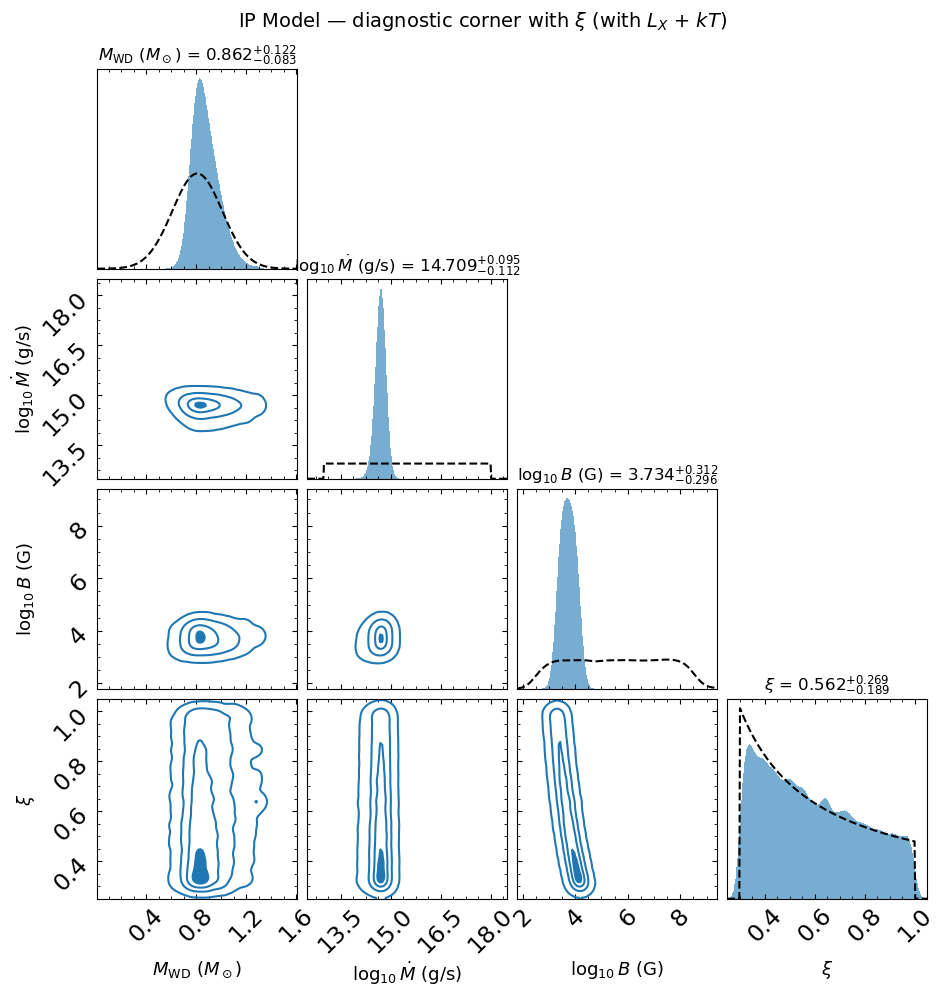

In [24]:
# --- Diagnostic 4D corner including xi (paper figure stays in cell above) ---
# Shows the xi marginal vs its log-uniform prior, and the xi-log10(B)
# anti-correlation (B ~ xi^-7/4 at fixed mu) that justifies marginalising
# xi rather than fixing it.

labels_ip4 = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
              r'$\log_{10} B$ (G)', r'$\xi$']
span_ip4 = list(span_ip_wide) + [(XI_LO - 0.05, XI_HI + 0.05)]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B, span=span_ip4, labels=labels_ip4,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    quantiles=None, show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)

# Prior overlays on all four diagonals
ax = axes[0, 0]
M_grid4 = np.linspace(*span_ip4[0], 300)
overlay_prior(ax, M_grid4, norm.pdf(M_grid4, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')

ax = axes[1, 1]
Mdot_grid4 = np.linspace(*span_ip4[1], 300)
Mdot_pdf4 = np.where((Mdot_grid4 >= LOGMDOT_LO) & (Mdot_grid4 <= LOGMDOT_HI),
                     1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid4, Mdot_pdf4, color='k', ls='--', lw=1.5)

ax = axes[2, 2]
B_grid4 = np.linspace(*span_ip4[2], 300)
overlay_prior(ax, B_grid4, kde_B(B_grid4), color='k', ls='--', lw=1.5)

# xi log-uniform prior: p(xi) = 1 / [xi * ln(xi_hi / xi_lo)] on [xi_lo, xi_hi]
ax = axes[3, 3]
xi_grid = np.linspace(*span_ip4[3], 300)
xi_pdf = np.where(
    (xi_grid >= XI_LO) & (xi_grid <= XI_HI),
    1.0 / (xi_grid * np.log(XI_HI / XI_LO)),
    0.0,
)
overlay_prior(ax, xi_grid, xi_pdf, color='k', ls='--', lw=1.5)

fig.suptitle(r'IP Model — diagnostic corner with $\xi$ (with $L_X$ + $kT$)',
             fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_spectral_with_xi.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


### Predicted $\dot{P}$ Distribution

IP pushforward:  Pdot = -1.44e-16  (+1.45e-16 / -2.63e-16)
                 range = [-4.98e-15, 1.41e-15]
                 99.2% within 1-sigma of Pdot=0;  100.0% within 2-sigma
IP full PPD:     66.9% within 1-sigma;  94.6% within 2-sigma


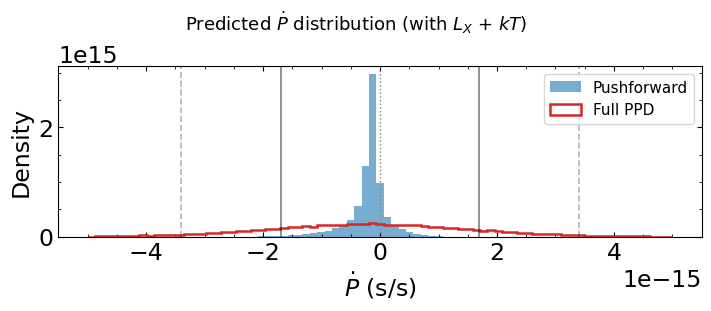

In [25]:
# Compute Pdot from posterior samples (pushforward of the deterministic forward model)
Pdot_ip_samples = np.array([
    pdot_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq
])

# Full posterior predictive: convolve pushforward with measurement noise N(0, sigma_Pdot^2)
rng_ppd = np.random.Generator(np.random.PCG64(123))
Pdot_ip_ppd = Pdot_ip_samples + rng_ppd.normal(0, sigma_Pdot, size=len(Pdot_ip_samples))

# --- Print summary statistics ---
med = np.median(Pdot_ip_samples)
lo, hi = np.percentile(Pdot_ip_samples, [16, 84])
mn, mx = Pdot_ip_samples.min(), Pdot_ip_samples.max()
print(f"IP pushforward:  Pdot = {med:.2e}  (+{hi-med:.2e} / {lo-med:.2e})")
print(f"                 range = [{mn:.2e}, {mx:.2e}]")
frac_consistent = np.mean(np.abs(Pdot_ip_samples) < sigma_Pdot) * 100
frac_2sig = np.mean(np.abs(Pdot_ip_samples) < 2*sigma_Pdot) * 100
print(f"                 {frac_consistent:.1f}% within 1-sigma of Pdot=0;  {frac_2sig:.1f}% within 2-sigma")

frac_ppd_1 = np.mean(np.abs(Pdot_ip_ppd) < sigma_Pdot) * 100
frac_ppd_2 = np.mean(np.abs(Pdot_ip_ppd) < 2*sigma_Pdot) * 100
print(f"IP full PPD:     {frac_ppd_1:.1f}% within 1-sigma;  {frac_ppd_2:.1f}% within 2-sigma")

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(-5e-15, 5e-15, 80)

# Pushforward (filled) and full PPD (step outline)
ax.hist(Pdot_ip_samples, bins=bins, density=True, alpha=0.6, color='C0',
        label='Pushforward')
ax.hist(Pdot_ip_ppd, bins=bins, density=True, histtype='step', color='C3', lw=1.8,
        label='Full PPD')

ax.axvline(0, color='gray', ls=':', lw=1)
for nsig, ls, alph in [(1, '-', 0.5), (2, '--', 0.3)]:
    ax.axvline(nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
    ax.axvline(-nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
ax.legend(fontsize=11)
ax.set_ylabel('Density')
ax.set_xlabel(r'$\dot{P}$ (s/s)')
fig.suptitle(r'Predicted $\dot{P}$ distribution (with $L_X$ + $kT$)', fontsize=13)
fig.savefig(f'{savedir}/bayesian_pdot_posterior_spectral.pdf', bbox_inches='tight')
plt.show()


### Posterior Predictive Check

Compare the predicted observables ($kT$, $L_X$) from the posterior to the observed values.
This verifies the models actually reproduce the spectral data, and shows the per-observable
$\chi^2$ contribution.

=== Per-observable chi^2 across IP posterior samples ===

(50th, 84th, 95th, 99th percentile)
  chi2(Pdot) =   0.01    0.08    0.32    0.91
  chi2(kT)   =   0.44    1.92    3.73    6.52
  chi2(L_X)  =   0.51    2.16    4.31    7.40
  total median = 1.51


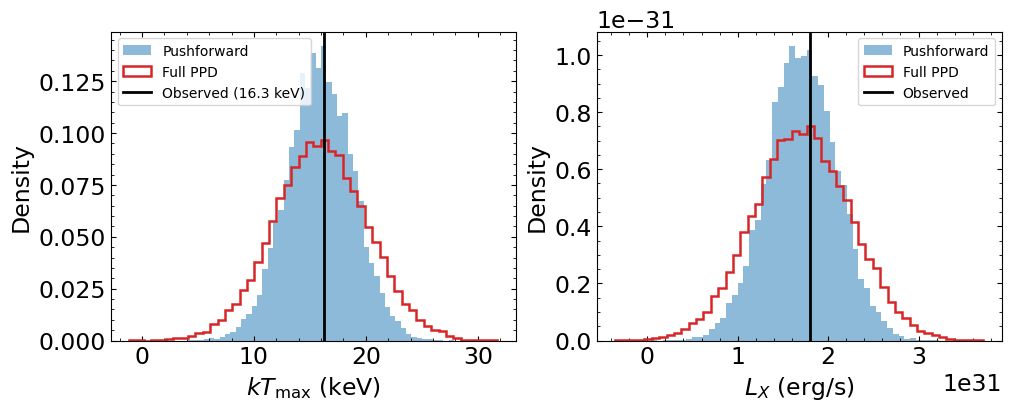

In [26]:
# --- Predicted kT and L_X from posterior (pushforward) ---
kT_ip_pred = np.array([kT_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq])
LX_ip_pred = np.array([LX_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq])

# Full PPD: convolve pushforward with the corresponding measurement noise
rng_ppd_kTLX = np.random.Generator(np.random.PCG64(124))
kT_ip_ppd = kT_ip_pred + rng_ppd_kTLX.normal(0, sigma_kT, size=len(kT_ip_pred))
LX_ip_ppd = LX_ip_pred + rng_ppd_kTLX.normal(0, sigma_LX, size=len(LX_ip_pred))

# --- Chi-squared breakdown (percentiles: 50th, 84th, 95th, 99th) ---
# chi^2 is defined on the deterministic prediction f(theta), not on PPD draws -- keep pushforward.
print("=== Per-observable chi^2 across IP posterior samples ===\n")
chi2_Pdot = ((Pdot_obs - Pdot_ip_samples) / sigma_Pdot)**2
chi2_kT   = ((kT_obs   - kT_ip_pred)      / sigma_kT)**2
chi2_LX   = ((L_X_obs  - LX_ip_pred)      / sigma_LX)**2
print("(50th, 84th, 95th, 99th percentile)")
for label, x in [('chi2(Pdot)', chi2_Pdot), ('chi2(kT)  ', chi2_kT),
                 ('chi2(L_X) ', chi2_LX)]:
    p = np.percentile(x, [50, 84, 95, 99])
    print(f"  {label} = {p[0]:6.2f}  {p[1]:6.2f}  {p[2]:6.2f}  {p[3]:6.2f}")
print(f"  total median = {np.median(chi2_Pdot+chi2_kT+chi2_LX):.2f}")

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# kT panel
ax = axes[0]
ax.hist(kT_ip_pred, bins=50, density=True, alpha=0.5, color='C0',
        label='Pushforward')
ax.hist(kT_ip_ppd,  bins=50, density=True, histtype='step', color='C3', lw=1.8,
        label='Full PPD')
ax.axvline(kT_obs, color='k', lw=2, label=f'Observed ({kT_obs} keV)')
ax.set_xlabel(r'$kT_{\rm max}$ (keV)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

# L_X panel
ax = axes[1]
ax.hist(LX_ip_pred, bins=50, density=True, alpha=0.5, color='C0',
        label='Pushforward')
ax.hist(LX_ip_ppd,  bins=50, density=True, histtype='step', color='C3', lw=1.8,
        label='Full PPD')
ax.axvline(L_X_obs, color='k', lw=2, label='Observed')
ax.set_xlabel(r'$L_X$ (erg/s)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

#fig.suptitle('Posterior Predictive Check', fontsize=13)
fig.savefig(f'{savedir}/bayesian_predictive_check_spectral.pdf', bbox_inches='tight')
plt.show()


In [27]:
# --- r_m / r_co posterior (spin-equilibrium diagnostic) ---
rm_over_rco = np.zeros(len(samples_ip_eq))
for i, s in enumerate(samples_ip_eq):
    _, _, _, _, r_m_s, r_co_s = _rm_rco(s[0], s[1], s[2], s[3])
    rm_over_rco[i] = r_m_s / r_co_s

med_rr = np.median(rm_over_rco)
lo_rr, hi_rr = np.percentile(rm_over_rco, [16, 84])
print(f"r_m / r_co:  median = {med_rr:.3f}  ({lo_rr:.3f} -- {hi_rr:.3f}, 68%)")


r_m / r_co:  median = 0.717  (0.518 -- 0.902, 68%)


In [28]:
# --- Spin-evolution timescale tau = P / |Pdot| ---
tau_yr = P / np.abs(Pdot_ip_samples) / (365.25 * 86400)

med_tau = np.median(tau_yr)
lo_tau, hi_tau = np.percentile(tau_yr, [16, 84])
print(f"Spin-evolution timescale (IP):")
print(f"  tau = P/|Pdot|:  median = {med_tau:.2e} yr  ({lo_tau:.2e} -- {hi_tau:.2e}, 68%)")
print(f"  log10(tau/yr):   median = {np.log10(med_tau):.1f}")
if med_tau > 1e9:
    print(f"  >> Gyr: consistent with long-term spin equilibrium")


Spin-evolution timescale (IP):
  tau = P/|Pdot|:  median = 5.49e+09 yr  (2.01e+09 -- 1.25e+10, 68%)
  log10(tau/yr):   median = 9.7
  >> Gyr: consistent with long-term spin equilibrium


## $\dot{P}$ Leverage Check (spectral-only re-run)

To test whether $\dot{P}$ adds parameter leverage on top of the spectral observables, we re-run the inference with $\dot{P}$ **removed entirely** from the likelihood (kT + $L_X$ only).  If the spectral-only posterior matches the with-$\dot{P}$ posterior, then $\dot{P}$ is a consistency check rather than a constraint.


In [29]:
# --- Spectral-only comparison (drop Pdot) ---
print("Running IP nested sampling (spectral-only, no Pdot)...")
sampler_ip_so = dynesty.DynamicNestedSampler(
    lambda theta: log_likelihood_ip(theta, include_Pdot=False),
    prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(46))
)
sampler_ip_so.run_nested(print_progress=True)
results_ip_so = sampler_ip_so.results
print(f"IP (spec-only): logZ = {results_ip_so['logz'][-1]:.2f} +/- {results_ip_so['logzerr'][-1]:.2f}")

# Equal-weight samples
w_ip_so = np.exp(results_ip_so['logwt'] - results_ip_so['logz'][-1])
w_ip_so /= w_ip_so.sum()
samples_ip_so_eq = dyfunc.resample_equal(results_ip_so['samples'], w_ip_so)

# log B for IP spec-only
R_so = get_R(samples_ip_so_eq[:, 0])
log10_B_so = samples_ip_so_eq[:, 2] - 3 * np.log10(R_so)

# Side-by-side parameter comparison: with-Pdot vs spectral-only
print("\n=== IP parameter posteriors: with Pdot vs spectral-only ===")
hdr = f"{'Parameter':<22s} {'with Pdot':<28s} {'spectral-only':<28s}"
print(hdr); print("-" * len(hdr))
print(f"{'M_WD [Msun]':<22s} {fmt(samples_ip_eq, 0):<28s} {fmt(samples_ip_so_eq, 0):<28s}")
print(f"{'log10(Mdot)':<22s} {fmt(samples_ip_eq, 1):<28s} {fmt(samples_ip_so_eq, 1):<28s}")
print(f"{'log10(mu)':<22s} {fmt(samples_ip_eq, 2):<28s} {fmt(samples_ip_so_eq, 2):<28s}")
print(f"{'xi':<22s} {fmt(samples_ip_eq, 3):<28s} {fmt(samples_ip_so_eq, 3):<28s}")
mB1 = np.median(log10_B_samples_ip); l1, h1 = np.percentile(log10_B_samples_ip, [16, 84])
mB2 = np.median(log10_B_so);         l2, h2 = np.percentile(log10_B_so, [16, 84])
print(f"{'log10(B)':<22s} {mB1:.2f} (+{h1-mB1:.2f}/-{mB1-l1:.2f})            "
      f"{mB2:.2f} (+{h2-mB2:.2f}/-{mB2-l2:.2f})")


Running IP nested sampling (spectral-only, no Pdot)...


27213it [01:00, 451.24it/s, batch: 1 | bound: 3 | nc: 1 | ncall: 558891 | eff(%):  4.499 | loglstar: -1.962 < -0.001 < -0.489 | logz: -7.030 +/-  0.057 | stop:  0.716]                       


IP (spec-only): logZ = -7.02 +/- 0.05

=== IP parameter posteriors: with Pdot vs spectral-only ===
Parameter              with Pdot                    spectral-only               
--------------------------------------------------------------------------------
M_WD [Msun]            0.862 (+0.121/-0.084)        0.866 (+0.132/-0.085)       
log10(Mdot)            14.709 (+0.095/-0.111)       14.712 (+0.091/-0.112)      
log10(mu)              30.080 (+0.359/-0.331)       30.088 (+0.348/-0.338)      
xi                     0.562 (+0.270/-0.189)        0.548 (+0.280/-0.187)       
log10(B)               3.74 (+0.31/-0.30)            3.75 (+0.32/-0.31)


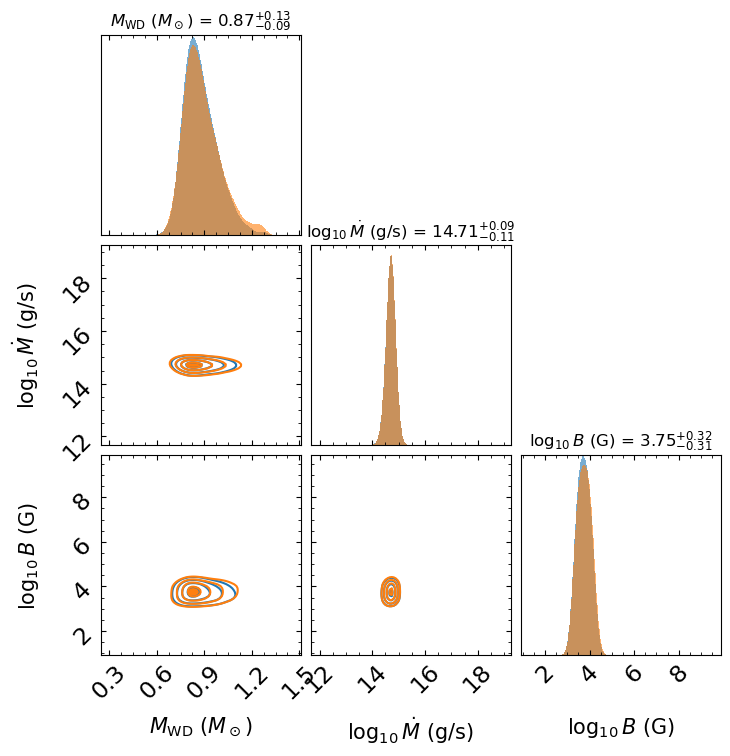

In [30]:
from matplotlib.lines import Line2D
# --- Overlay IP corner: with Pdot (blue) vs spectral-only (orange) ---
results_ip_B_full = _results_for_display(results_ip)
results_ip_B_so   = _results_for_display(results_ip_so)

all_ip_so = np.vstack([results_ip_B_full['samples'], results_ip_B_so['samples']])
span_so = []
for j in range(3):
    lo, hi = np.percentile(all_ip_so[:, j], [0.5, 99.5])
    w = hi - lo
    span_so.append((lo - 0.3 * w, hi + 0.3 * w))

labels_so = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B_full, dims=[0, 1, 2], span=span_so, labels=labels_so,
    quantiles=None, show_titles=False, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 16},
    color='C0',
)
dyplot.cornerplot(
    results_ip_B_so, dims=[0, 1, 2], span=span_so, labels=labels_so,
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 15},
    color='C1', fig=(fig, axes),
)
# fig.legend(handles=[
#     Line2D([0], [0], color='C0', lw=2, label=r'with $\dot P$'),
#     Line2D([0], [0], color='C1', lw=2, label=r'spectral only (no $\dot P$)'),
# ], loc='upper right', fontsize=11, frameon=True)
#fig.suptitle(r'IP: $\dot P$ leverage check', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_pdot_leverage.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


### Posterior-predictive $\dot{P}$ from the spectral-only fit

The corner overlay above shows the *symptom* (with-$\dot{P}$ vs spectral-only posteriors are nearly identical). The two panels below decompose the *cause* into two distinct objects:

- **Left — pushforward $\{f(\boldsymbol\theta^{(i)})\}$ (leverage diagnostic).** The Bayes update factor when adding the $\dot P$ likelihood is $\mathcal{L}(\dot P_{\rm obs}\mid\boldsymbol\theta) = \mathcal{N}(\dot P_{\rm obs}; f(\boldsymbol\theta),\sigma_{\dot P}^2)$, which depends on the *deterministic* forward-model output. The likelihood can only reweight the posterior to the extent that $f(\boldsymbol\theta)$ varies across the spectral-only posterior bulk relative to $\sigma_{\dot P}$. If the pushforward already sits inside $\pm\sigma_{\dot P}$, the Bayes update is uniform and no reweighting occurs.

- **Right — full posterior predictive $\{f(\boldsymbol\theta^{(i)}) + \mathcal{N}(0,\sigma_{\dot P}^2)\}$ (consistency check).** This is the predicted distribution of an actual $\dot P$ measurement under the spectral-only model. It answers the falsifiability question: would the observed value $\dot P_{\rm obs}=0$ be consistent with the model? By the law of total variance, $\sigma_{\rm PPD}^2 = \sigma_{\rm pushforward}^2 + \sigma_{\dot P}^2$, so the PPD is at least as broad as the pushforward — the difference is the parameter-independent measurement noise that cannot itself drive reweighting.

=== Predicted Pdot from spectral-only posterior ===
(measurement: Pdot_obs = 0, sigma_Pdot = 1.7e-15 s/s)

Pushforward: median = -1.49e-16   68% CI = [-4.92e-16, -4.29e-18]
             |Pdot| < 1 sigma_Pdot: 96.3%
             |Pdot| < 2 sigma_Pdot: 98.7%


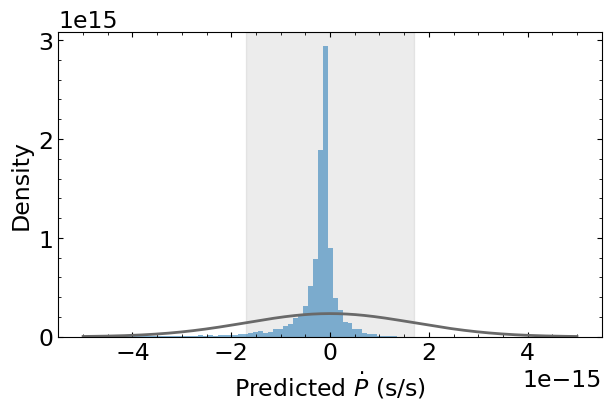

In [31]:
# =====================================================
# Pushforward of Pdot from the spectral-only posterior.
# Leverage diagnostic: if f(theta) varies less than
# sigma_Pdot across the posterior, the Pdot likelihood
# term cannot reweight it.
# =====================================================

Pdot_ip_so = np.array([pdot_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_so_eq])

def frac(samp, k):
    return 100 * np.mean(np.abs(samp) < k * sigma_Pdot)

print('=== Predicted Pdot from spectral-only posterior ===')
print(f'(measurement: Pdot_obs = 0, sigma_Pdot = {sigma_Pdot:.1e} s/s)\n')

med = np.median(Pdot_ip_so);  lo, hi = np.percentile(Pdot_ip_so, [16, 84])
print(f'Pushforward: median = {med:+.2e}   68% CI = [{lo:+.2e}, {hi:+.2e}]')
print(f'             |Pdot| < 1 sigma_Pdot: {frac(Pdot_ip_so, 1):.1f}%')
print(f'             |Pdot| < 2 sigma_Pdot: {frac(Pdot_ip_so, 2):.1f}%')

# --- Plot ---
bins = np.linspace(-5e-15, 5e-15, 100)
pdot_grid = np.linspace(bins[0], bins[-1], 400)

fig, ax = plt.subplots(figsize=(6, 4))
#ax.set_yscale('log')
ax.axvspan(-sigma_Pdot, sigma_Pdot, color='gray', alpha=0.15, zorder=0)
ax.hist(Pdot_ip_so, bins=bins, density=True, alpha=0.55, color='C0',
        label='Pushforward')
#ax.axvline(0, color='black', ls=':', lw=2)
ax.plot(pdot_grid, norm.pdf(pdot_grid, Pdot_obs, sigma_Pdot),
        color='dimgray', lw=2, label='Obs Gaussian')
ax.set_xlabel(r'Predicted $\dot{P}$ (s/s)')
ax.set_ylabel('Density')
#ax.set_title('Pushforward: leverage diagnostic', fontsize=12)
#ax.legend(fontsize=10, loc='upper right')

fig.savefig(f'{savedir}/bayesian_predictive_pdot_specOnly.pdf', bbox_inches='tight')
plt.show()